# Telemetry and load

Every response explains its own latency. This notebook reads that record, then puts the service under load while the
monitoring stack watches the same jobs and the resources behind them.

The load sections work without monitoring. To see the Grafana view, start it first:

```bash
cd monitoring && ./up.sh
```

In [1]:
from qputwin_demo import *

connect();

QPUTwin at http://localhost:8000: ready, 7 twins reachable


## One job, fourteen spans

Durations are measured in one process with a monotonic clock, and workers report durations rather than timestamps, so
clock differences between containers cannot enter. The fourteen spans sum to the round trip.

In [2]:
result = run("quantinuum_helios", ghz(12))
telemetry = result["telemetry"]
table = span_table(telemetry)

print(f"Round trip:           {telemetry['total_roundtrip_ms']:.3f} ms")
print(f"Sum of the 14 spans:  {table.ms.sum():.3f} ms")
b = telemetry["breakdown"]
print(f"total = orchestration + worker:  difference {telemetry['total_roundtrip_ms'] - telemetry['orchestration_overhead_ms'] - b['worker_service_ms']:+.6f} ms")
print(f"dispatch = network + worker:     difference {b['dispatch_rtt_ms'] - b['network_transit_ms'] - b['worker_service_ms']:+.6f} ms")
print(f"QPU = simulation + sampling:     difference {telemetry['qpu_compute_time_ms'] - b['simulation_ms'] - b['sampling_ms']:+.6f} ms")
table

Round trip:           7.240 ms
Sum of the 14 spans:  7.242 ms
total = orchestration + worker:  difference +0.000000 ms
dispatch = network + worker:     difference +0.000000 ms
QPU = simulation + sampling:     difference -0.000000 ms


,ms,share %
span,,
ingress,0.372,5.1
validation,0.676,9.3
backend selection,0.028,0.4
orchestrator queue,0.000,0.0
network,2.249,31.1
worker queue,0.003,0.0
parse,0.654,9.0
SABRE routing,0.000,0.0
native compile,1.287,17.8


## Where small jobs spend their time

Averaging forty jobs on each twin shows a result that matters for quantum cloud studies: for a small circuit, the
emulation layer costs more than the simulation.

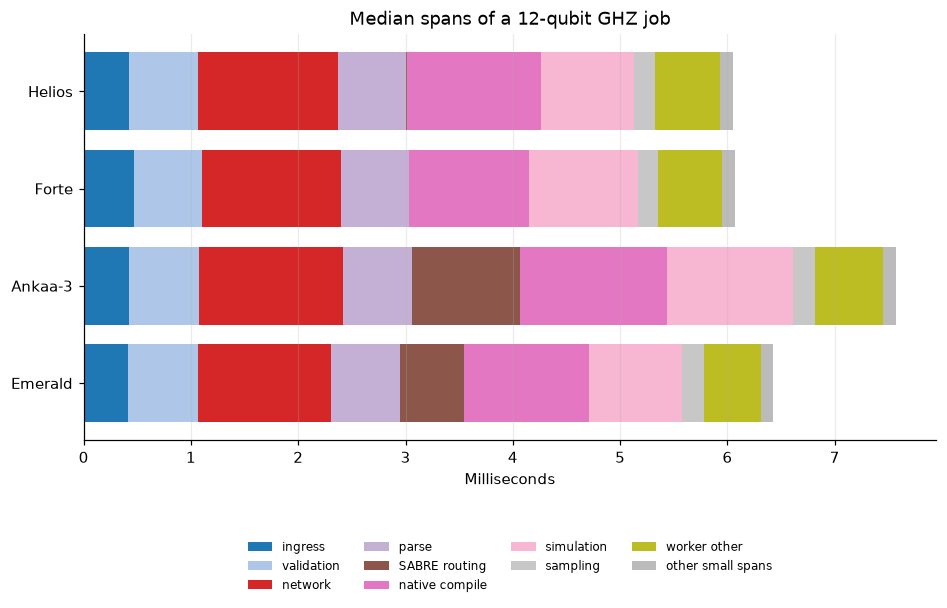

In [3]:
rows = {}
for backend in BACKENDS:
    jobs = [run(backend, ghz(12), routing=True, seed=i)["telemetry"]["breakdown"] for i in range(40)]
    rows[NAMES[backend]] = {key: float(np.median([j[key] for j in jobs])) for key in SPANS}
plot_spans(rows, "Median spans of a 12-qubit GHZ job")

## As circuits grow, simulation takes over

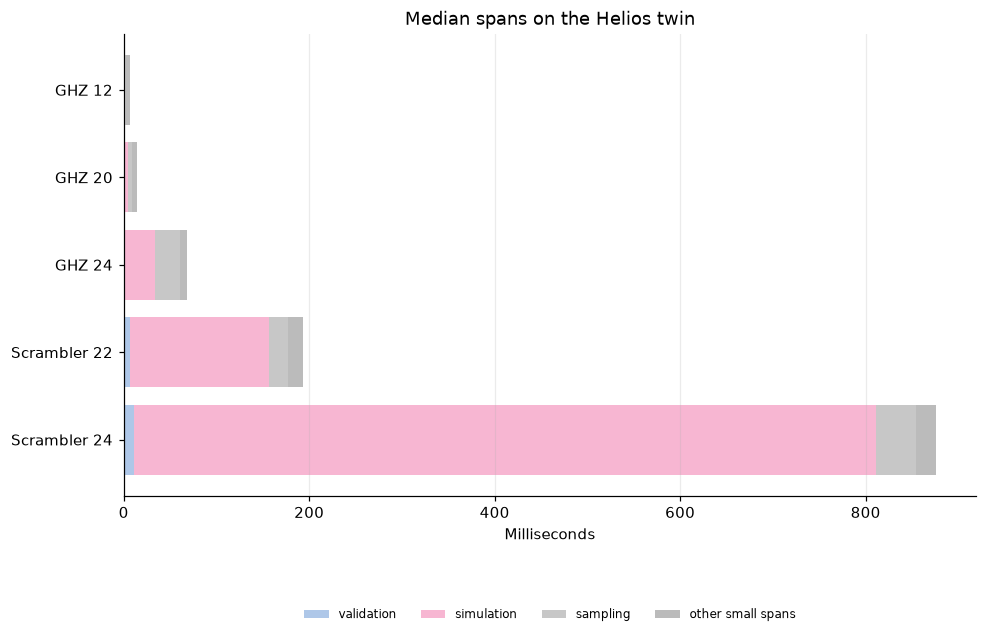

In [4]:
rows = {}
for label, circuit in {"GHZ 12": ghz(12), "GHZ 20": ghz(20), "GHZ 24": ghz(24), "Scrambler 22": scrambler(22, 6), "Scrambler 24": scrambler(24, 8)}.items():
    jobs = [run("quantinuum_helios", circuit, seed=i)["telemetry"]["breakdown"] for i in range(5)]
    rows[label] = {key: float(np.median([j[key] for j in jobs])) for key in SPANS}
plot_spans(rows, "Median spans on the Helios twin")

## What the service exposes

`GET /metrics` serves Prometheus metrics and `GET /v1/telemetry/summary` serves live statistics per twin. Both count
every job since the orchestrator last started, so after the earlier notebooks these tables mix small and heavy jobs.

In [5]:
print(metrics_text("qputwin_jobs_total{"))

qputwin_jobs_total{backend="google_willow",status="COMPLETED",mode="sync"} 22
qputwin_jobs_total{backend="ibm_heron",status="COMPLETED",mode="sync"} 28
qputwin_jobs_total{backend="ibm_nighthawk",status="COMPLETED",mode="sync"} 22
qputwin_jobs_total{backend="ionq_forte",status="COMPLETED",mode="async"} 4
qputwin_jobs_total{backend="ionq_forte",status="COMPLETED",mode="sync"} 40
qputwin_jobs_total{backend="iqm_emerald",status="COMPLETED",mode="sync"} 58
qputwin_jobs_total{backend="quantinuum_helios",status="COMPLETED",mode="sync"} 66
qputwin_jobs_total{backend="rigetti_ankaa_3",status="COMPLETED",mode="sync"} 40


In [6]:
summary = httpx.get(f"{API_URL}/v1/telemetry/summary").json()["summary"]
pd.DataFrame({NAMES[b]: {"Jobs": s["jobs"], "Rejected": s["rejected"], "Failed": s["failed"],
                         "Median round trip (ms)": round(s["metrics"]["total_roundtrip_ms"]["median"], 2),
                         "p95 round trip (ms)": round(s["metrics"]["total_roundtrip_ms"]["p95"], 2)}
              for b, s in summary.items() if b in NAMES}).T

,Jobs,Rejected,Failed,Median round trip (ms),p95 round trip (ms)
Willow,22.0,0.0,0.0,20.06,193.50
Heron r3,28.0,0.0,0.0,18.43,58.57
Nighthawk,22.0,0.0,0.0,18.78,93.76
Forte,44.0,0.0,0.0,6.05,35288.21
Emerald,58.0,0.0,0.0,6.59,19.75
Helios,66.0,0.0,0.0,6.23,866.04
Ankaa-3,40.0,0.0,0.0,7.65,8.65


## Load test

A closed loop: each client sends one job, waits for the answer, and repeats. Latency is measured at the client, because
server telemetry cannot see time spent waiting to be accepted. Throughput from this notebook is limited by Python
threads and runs on the same machine as the stack, so treat it as a live illustration, not a benchmark. The paper's
figures come from the multi-process load generator in `benchmarks/`.

Open the **QPUTwin Overview** dashboard before running this cell to watch it live.

In [7]:
from concurrent.futures import ThreadPoolExecutor

circuit = ghz(12)
payloads = [body(b, circuit, shots=256, routing=True) for b in BACKENDS]

def client(index, deadline):
    latencies, errors = [], 0
    with httpx.Client(base_url=API_URL, timeout=30) as http:
        turn = index
        while time.perf_counter() < deadline:
            start = time.perf_counter()
            response = http.post("/v1/jobs", json=payloads[turn % 4])
            latencies.append(time.perf_counter() - start)
            errors += response.status_code != 200
            turn += 1
    return latencies, errors

def level(clients, seconds=10):
    deadline = time.perf_counter() + seconds
    with ThreadPoolExecutor(clients) as pool:
        results = list(pool.map(lambda i: client(i, deadline), range(clients)))
    latencies = np.concatenate([r[0] for r in results]) * 1000
    return {"Clients": clients, "Jobs/s": round(len(latencies) / seconds, 1), "Median (ms)": round(float(np.median(latencies)), 1),
            "p95 (ms)": round(float(np.percentile(latencies, 95)), 1), "Errors": sum(r[1] for r in results)}

load_started = time.time()
load = pd.DataFrame([level(c) for c in (1, 2, 4, 8, 16)]).set_index("Clients")
load

,Jobs/s,Median (ms),p95 (ms),Errors
Clients,,,,
1,121.6,8.0,9.9,0
2,197.5,9.6,14.7,0
4,285.0,13.3,21.0,0
8,360.2,21.4,33.2,0
16,368.0,42.0,58.1,0


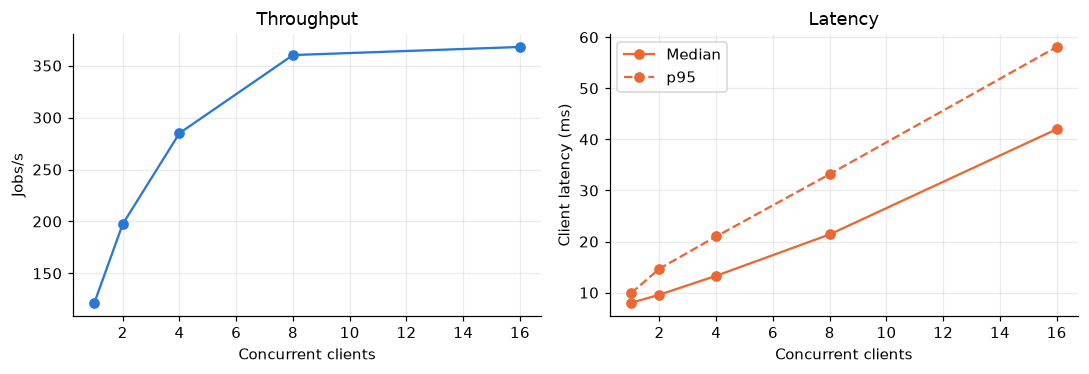

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(load.index, load["Jobs/s"], "o-", color=COLORS["quantinuum_helios"])
axes[0].set(xlabel="Concurrent clients", ylabel="Jobs/s", title="Throughput")
axes[1].plot(load.index, load["Median (ms)"], "o-", label="Median", color=COLORS["ionq_forte"])
axes[1].plot(load.index, load["p95 (ms)"], "o--", label="p95", color=COLORS["ionq_forte"])
axes[1].set(xlabel="Concurrent clients", ylabel="Client latency (ms)", title="Latency")
axes[1].legend()
fig.tight_layout()
plt.show()

## What the machine was doing

Prometheus recorded those jobs and the resources behind them, so one test can be read as a single timeline: job rate,
container CPU and memory, and whole-host CPU. The four job-rate lines overlap because the clients cycle through the twins
in turn, so each twin receives the same load.

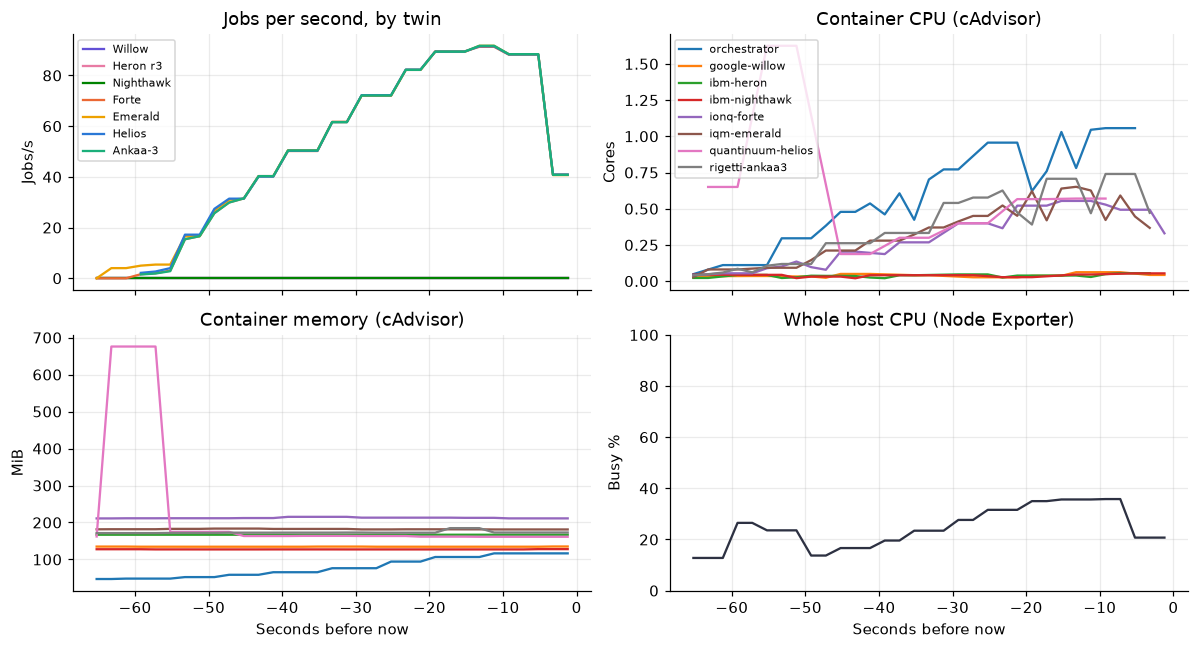

In [9]:
window = time.time() - load_started + 15
time.sleep(10)
rate = prometheus_range("sum by (backend) (rate(qputwin_jobs_total[15s]))", window)

if rate is None or rate.empty:
    print("Prometheus is not reachable. Start the monitoring stack with: cd monitoring && ./up.sh")
else:
    cpu = prometheus_range('sum by (service) (rate(container_cpu_usage_seconds_total{project="qputwin"}[15s]))', window)
    memory = prometheus_range('sum by (service) (container_memory_working_set_bytes{project="qputwin"})', window)
    host = prometheus_range('1 - avg(rate(node_cpu_seconds_total{mode="idle"}[15s]))', window)

    fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
    for backend, group in rate.groupby("backend"):
        axes[0, 0].plot(group.t, group.value, color=COLORS.get(backend), label=NAMES.get(backend, backend))
    axes[0, 0].set(title="Jobs per second, by twin", ylabel="Jobs/s")
    for service, group in cpu.groupby("service"):
        axes[0, 1].plot(group.t, group.value, label=service.replace("worker-", ""))
    axes[0, 1].set(title="Container CPU (cAdvisor)", ylabel="Cores")
    for service, group in memory.groupby("service"):
        axes[1, 0].plot(group.t, group.value / 2**20, label=service.replace("worker-", ""))
    axes[1, 0].set(title="Container memory (cAdvisor)", ylabel="MiB", xlabel="Seconds before now")
    axes[1, 1].plot(host.t, host.value * 100, color="#2D3142")
    axes[1, 1].set(title="Whole host CPU (Node Exporter)", ylabel="Busy %", xlabel="Seconds before now", ylim=(0, 100))
    for ax in (axes[0, 0], axes[0, 1]):
        ax.legend(fontsize=7)
    fig.tight_layout()
    plt.show()

In [10]:
print("Grafana dashboards:")
for name, uid in [("QPUTwin Overview", "qputwin-overview"), ("Latency Decomposition", "qputwin-latency"), ("Workload", "qputwin-workload"),
                  ("Jobs and Resources", "qputwin-resources"), ("Containers", "qputwin-containers"), ("Host", "qputwin-host")]:
    print(f"  {name:24} {GRAFANA_URL}/d/{uid}")

Grafana dashboards:
  QPUTwin Overview         http://localhost:3000/d/qputwin-overview
  Latency Decomposition    http://localhost:3000/d/qputwin-latency
  Workload                 http://localhost:3000/d/qputwin-workload
  Jobs and Resources       http://localhost:3000/d/qputwin-resources
  Containers               http://localhost:3000/d/qputwin-containers
  Host                     http://localhost:3000/d/qputwin-host
